In [1]:
suppressMessages(library(DESeq2))
suppressMessages(library(ggplot2))

In [2]:
df <- read.csv("../../results/10_compare_with_public_data/01_create_pseudo_bulk/pseudo_bulk_counts.csv", 
row.names = 1)

In [3]:
dim(df)

[1] 18085    12

In [4]:
mt_genes <- grepl("^MT-", rownames(df))
df <- df[!mt_genes, ]

In [5]:
dim(df)

[1] 18074    12

In [6]:
coldata <- data.frame(
  condition = c("SRC", "SRC", "SRC", "SRC", "SRC",
  "Normal", "Normal", "Normal",
  "LN", "LN", "LN", "LN"),
  row.names = c("sample_15837", "sample_15852", "sample_16512", "sample_21022", "sample_8262",
  "sample_B23.03794.5", "sample_B23.05785.7.1", "sample_B23.05785.7.2",
  "sample_X1842","sample_X1845", "sample_X1899", "sample_X1912")
)

In [7]:
head(coldata)

,condition
,<chr>
sample_15837,SRC
sample_15852,SRC
sample_16512,SRC
sample_21022,SRC
sample_8262,SRC
sample_B23.03794.5,Normal


In [8]:
dds <- DESeqDataSetFromMatrix(
  countData = df,
  colData = coldata,
  design = ~ condition
)

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”


In [9]:
dds

class: DESeqDataSet 
dim: 18074 12 
metadata(1): version
assays(1): counts
rownames(18074): SAMD11 NOC2L ... EIF1AY DAZ2
rowData names(0):
colnames(12): sample_15837 sample_15852 ... sample_X1899 sample_X1912
colData names(1): condition

In [10]:
# optional but recommended: remove very low-count genes
keep <- rowSums(counts(dds) >= 10) >= 5
dds <- dds[keep, ]

# run DESeq pipeline
dds <- DESeq(dds)

# variance stabilizing transform
vsd <- vst(dds, blind = FALSE)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [11]:
vsd

class: DESeqTransform 
dim: 18003 12 
metadata(1): version
assays(1): ''
rownames(18003): SAMD11 NOC2L ... KDM5D EIF1AY
rowData names(26): baseMean baseVar ... maxCooks dispFit
colnames(12): sample_15837 sample_15852 ... sample_X1899 sample_X1912
colData names(2): condition sizeFactor

using ntop=18000 top features by variance



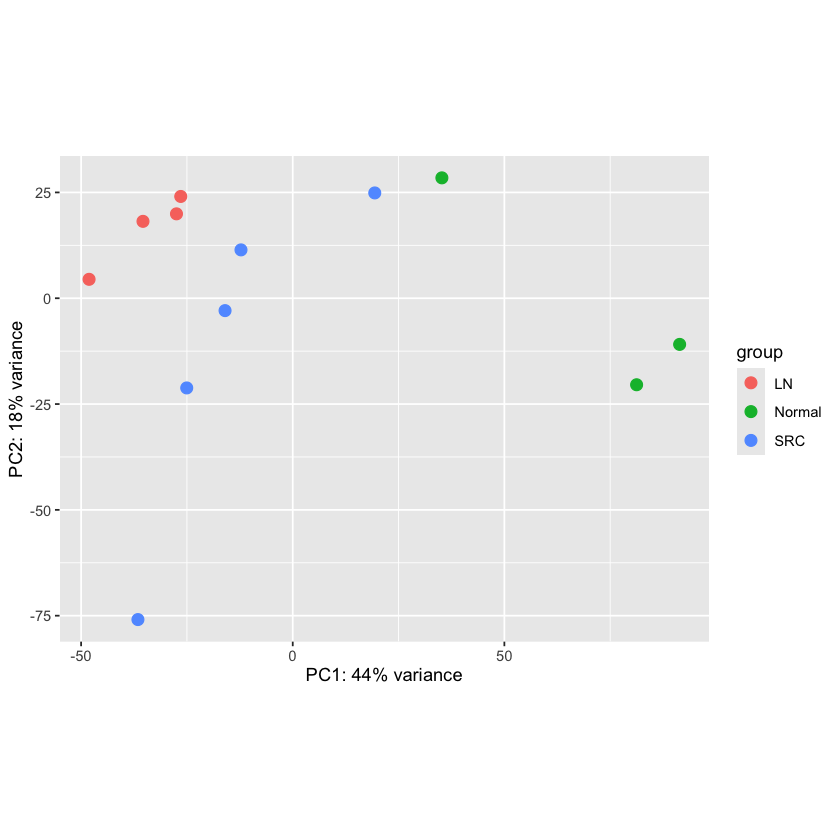

In [12]:
# quick PCA using DESeq2
plotPCA(vsd, ntop=18000, intgroup = "condition")